# GIAI ĐOẠN 3A: EDA ĐƠN BIẾN & TỔNG QUAN DÒNG TIỀN
## Descriptive Analytics: Phân tích Phân phối, Chân dung Khách hàng & Thiệt hại Nguồn vốn
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM & Gartner Descriptive Analytics

---


## 1. Mục tiêu & Cấu trúc Phân tích Đơn biến
Theo chuẩn phân tích doanh nghiệp của Gartner, tầng **Descriptive Analytics (Mô tả)** trả lời câu hỏi cốt lõi: *"Chuyện gì đã và đang xảy ra trong danh mục khách hàng của BB Bank?"*
* Khám phá phân phối thống kê (Mean, Median, IQR, Skewness, Kurtosis) của toàn bộ các biến số và biến phân loại.
* Đối chiếu hai thước đo cơ sở: **Tỷ lệ mất khách hàng (Headcount Churn Rate)** vs **Tỷ lệ mất dòng tiền gửi (Deposit Volume at Risk)**.
* Lưu biểu đồ xuất bản vào thư mục `reports/figures/`.


In [1]:
import os
import sys

# Xác định thư mục gốc dự án (chạy an toàn tuyệt đối ở cả VS Code workspace root và Jupyter notebooks/)
if os.path.exists('src'):
    PROJECT_ROOT = os.path.abspath('.')
elif os.path.exists(os.path.join('..', 'src')):
    PROJECT_ROOT = os.path.abspath('..')
else:
    PROJECT_ROOT = os.path.abspath('.')

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import os
import sys

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách đồ thị chuẩn của Thầy
plt.style.use('ggplot')
%matplotlib inline

onefig_size = (10, 4)
multifigs_size = (12, 4)

# Thư mục lưu biểu đồ
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# Nạp dữ liệu sạch kỹ thuật từ data/interim/
INTERIM_PATH = os.path.join(PROJECT_ROOT, 'data', 'interim', 'churn_technical_cleaned.csv')
df = pd.read_csv(INTERIM_PATH)

print(f"Đã nạp dữ liệu sạch kỹ thuật: {df.shape[0]:,} dòng x {df.shape[1]} cột")
df.head(3)


Đã nạp dữ liệu sạch kỹ thuật: 10,000 dòng x 19 cột


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned,Surname_Encoding_Issue
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,0
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377,0


## 2. Phân tích Biến Mục tiêu (`Exited`) & Đối chiếu Dòng tiền Rủi ro

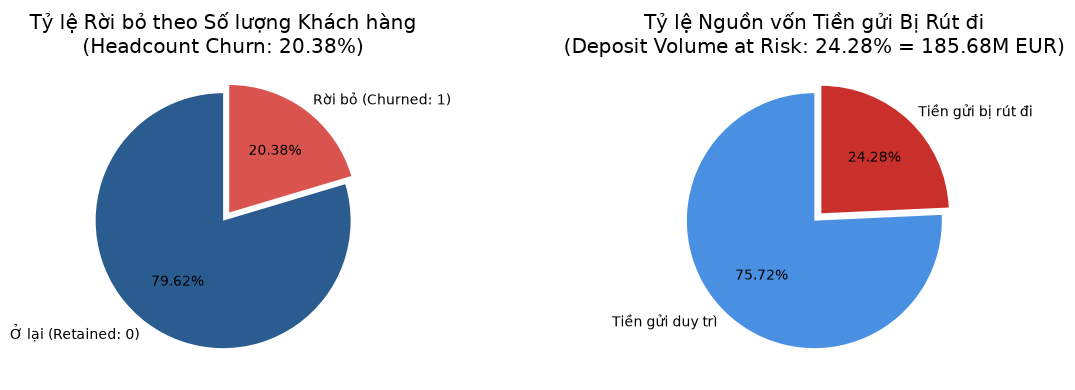

Tổng số dư tiền gửi toàn ngân hàng: 764,858,892.88 EUR
Số dư tiền gửi của khách hàng rời bỏ: 185,681,112.10 EUR (24.28%)
Số dư TB khách hàng ở lại: 72,742.75 EUR
Số dư TB khách hàng rời bỏ: 91,109.48 EUR (cao hơn 25.2%!)


In [2]:
fig, axs = plt.subplots(ncols=2, figsize=multifigs_size)

# Biểu đồ 1: Headcount Churn
churn_counts = df['Exited'].value_counts()
labels = ['Ở lại (Retained: 0)', 'Rời bỏ (Churned: 1)']
colors = ['#2b5c8f', '#d9534f']
axs[0].pie(churn_counts, labels=labels, autopct='%1.2f%%', startangle=90, colors=colors, explode=(0, 0.08))
axs[0].set_title("Tỷ lệ Rời bỏ theo Số lượng Khách hàng\n(Headcount Churn: 20.38%)")

# Biểu đồ 2: Deposit Volume at Risk
total_balance = df['Balance'].sum()
churn_balance = df[df['Exited'] == 1]['Balance'].sum()
retained_balance = total_balance - churn_balance
bal_data = [retained_balance, churn_balance]

axs[1].pie(bal_data, labels=['Tiền gửi duy trì', 'Tiền gửi bị rút đi'], autopct='%1.2f%%', startangle=90, colors=['#4a90e2', '#c9302c'], explode=(0, 0.08))
axs[1].set_title("Tỷ lệ Nguồn vốn Tiền gửi Bị Rút đi\n(Deposit Volume at Risk: 24.28% = 185.68M EUR)")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'fig_01_target_distribution.png')
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Tổng số dư tiền gửi toàn ngân hàng: {total_balance:,.2f} EUR")
print(f"Số dư tiền gửi của khách hàng rời bỏ: {churn_balance:,.2f} EUR ({churn_balance*100/total_balance:.2f}%)")
print(f"Số dư TB khách hàng ở lại: {df[df['Exited']==0]['Balance'].mean():,.2f} EUR")
print(f"Số dư TB khách hàng rời bỏ: {df[df['Exited']==1]['Balance'].mean():,.2f} EUR (cao hơn 25.2%!)")


**Observations**:
- Tỷ lệ rời bỏ về mặt con người là **20,38%** (2.038 khách hàng).
- Tỷ lệ thất thoát về quy mô tiền gửi lên tới **24,28%** (**185,68 triệu EUR**).
- Khách hàng rời bỏ có số dư trung bình **91.109 EUR**, cao hơn 25,2% so với khách hàng ở lại (72.743 EUR).

**Conclusion**:
BB Bank không chỉ đơn thuần mất đi 1/5 lượng tài khoản đại trà, mà đang chịu tổn thất nặng nề ở phân khúc khách hàng giàu có (Affluent/VIP).


## 3. Phân tích Phân phối Thuộc tính Số (Numerical Variables)

In [3]:
num_cols = ['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Tenure', 'Point_Earned']

stats_df = []
for c in num_cols:
    s = df[c]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    stats_df.append({
        'Biến số': c,
        'Mean': s.mean(),
        'Std': s.std(),
        'Median': s.median(),
        'IQR': q3 - q1,
        'Min': s.min(),
        'Max': s.max(),
        'Skewness': s.skew(),
        'Kurtosis': s.kurtosis()
    })

display(pd.DataFrame(stats_df).round(2))


,Biến số,Mean,Std,Median,IQR,Min,Max,Skewness,Kurtosis
0,Age,38.92,10.49,37.00,12.00,18.00,92.00,1.01,1.40
1,CreditScore,650.53,96.65,652.00,134.00,350.00,850.00,-0.07,-0.43
2,Balance,76485.89,62397.41,97198.54,127644.24,0.00,250898.09,-0.14,-1.49
3,EstimatedSalary,100090.24,57510.49,100193.92,98386.14,11.58,199992.48,0.00,-1.18
4,Tenure,5.01,2.89,5.00,4.00,0.00,10.00,0.01,-1.17
5,Point_Earned,606.52,225.92,605.00,391.00,119.00,1000.00,0.01,-1.19


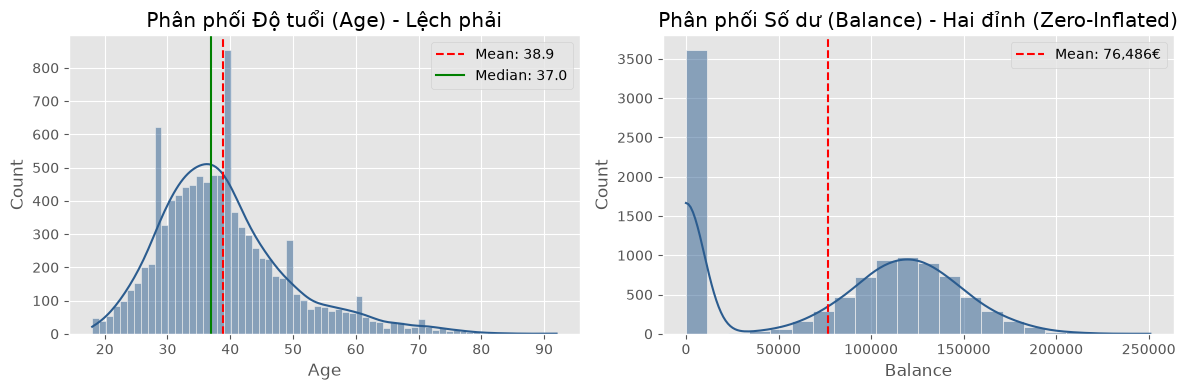

In [4]:
fig, axs = plt.subplots(ncols=2, figsize=multifigs_size)

# Phân phối Age
sns.histplot(df['Age'], kde=True, ax=axs[0], color='#2b5c8f')
axs[0].axvline(df['Age'].mean(), color='red', linestyle='--', label=f"Mean: {df['Age'].mean():.1f}")
axs[0].axvline(df['Age'].median(), color='green', linestyle='-', label=f"Median: {df['Age'].median():.1f}")
axs[0].set_title("Phân phối Độ tuổi (Age) - Lệch phải")
axs[0].legend()

# Phân phối Balance
sns.histplot(df['Balance'], kde=True, ax=axs[1], color='#2b5c8f')
axs[1].axvline(df['Balance'].mean(), color='red', linestyle='--', label=f"Mean: {df['Balance'].mean():,.0f}€")
axs[1].set_title("Phân phối Số dư (Balance) - Hai đỉnh (Zero-Inflated)")
axs[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_02_balance_age_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()


**Observations**:
- `Age`: Lệch phải (Skewness = 1.01), tập trung chủ yếu ở độ tuổi 30–44, trung vị là 37 tuổi.
- `Balance`: Phân phối hai đỉnh rất rõ ràng (Bimodal Zero-Inflated): Một đỉnh khổng lồ tập trung tại điểm `0` (3.617 khách hàng) và một phân phối chuẩn đối xứng quanh mức `120.000 EUR`.
- `CreditScore`: Phân phối gần chuẩn quanh 650 điểm nhưng bị chặn trần (right-censored) tại mốc 850 điểm.
- `EstimatedSalary`: Phân phối đều (Uniform Distribution) trải dài từ 11 EUR đến gần 200.000 EUR.

**Conclusion**:
Hiện tượng Zero-Inflation ở cột Balance là đặc trưng quan trọng nhất cần tách biệt ở bước Feature Engineering (`IsZeroBalance`), và phân phối tuổi cho thấy ngân hàng phục vụ cả người đi làm trẻ tuổi lẫn người hưu trí.


## 4. Phân tích Thuộc tính Phân loại & Trải nghiệm (Categorical & Experience Variables)

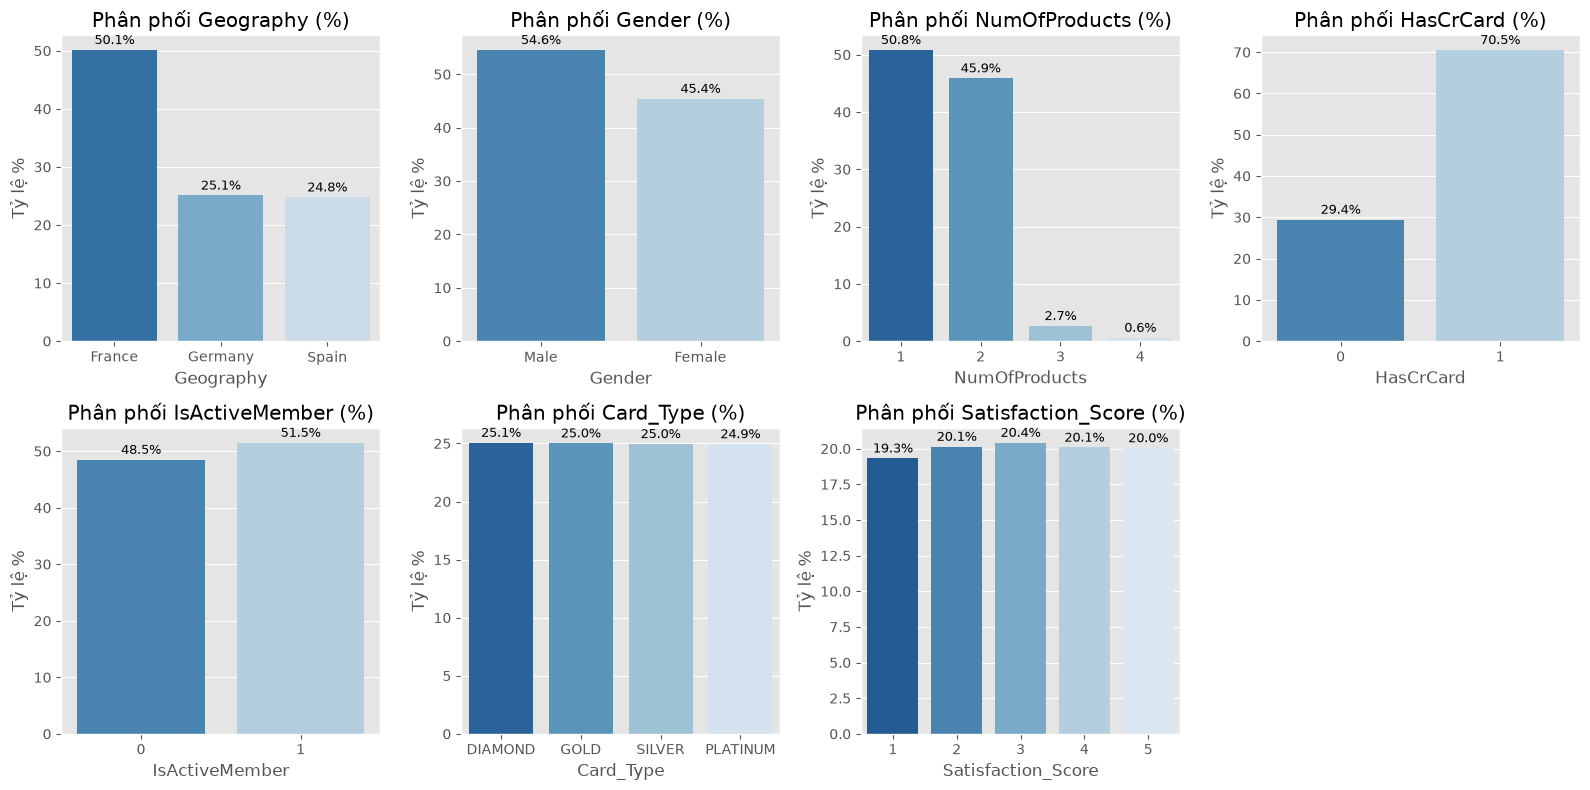

In [5]:
cat_features = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Card_Type', 'Satisfaction_Score']

fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axs = axs.flatten()

for i, col in enumerate(cat_features):
    counts = df[col].value_counts(normalize=True) * 100
    sns.barplot(x=counts.index, y=counts.values, hue=counts.index, ax=axs[i], palette='Blues_r', legend=False)
    axs[i].set_title(f"Phân phối {col} (%)")
    axs[i].set_ylabel("Tỷ lệ %")
    for p in axs[i].patches:
        axs[i].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# Ẩn subplot thứ 8 thừa
axs[-1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_03_demographics_univariate.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observations**:
- `Geography`: Pháp chiếm đa số tuyệt đối (**50,14%**), Đức và Tây Ban Nha mỗi nước xấp xỉ một phần tư (**25,09%** và **24,77%**).
- `Gender`: Nam giới chiếm 54,57%, Nữ giới chiếm 45,43%.
- `NumOfProducts`: 96,74% khách hàng chỉ sử dụng 1 hoặc 2 sản phẩm (1 SP: 50,84%, 2 SP: 45,90%). Chỉ có 2,66% khách hàng mở 3 sản phẩm và 0,60% mở 4 sản phẩm.
- `HasCrCard`: 70,55% khách hàng sở hữu thẻ tín dụng.
- `IsActiveMember`: Tỷ lệ thành viên hoạt động và không hoạt động gần như tương đương (51,51% active vs 48,49% inactive).
- `Card_Type`: Phân bố gần như đồng đều 25% cho mỗi hạng thẻ (Diamond, Gold, Silver, Platinum).
- `Satisfaction_Score`: Phân bố đồng đều ~20% cho mỗi mức từ 1 đến 5 sao.

**Conclusion**:
Danh mục sản phẩm của ngân hàng chủ yếu xoay quanh 1–2 gói cơ bản. Nhóm sử dụng 3–4 sản phẩm có quy mô rất nhỏ (326 khách hàng) nhưng sẽ là tâm điểm chẩn đoán ở phân tích nhị biến tiếp theo.
